# 18 - Multi-well / Field Study

**Part B - Petrophys Curriculum**

Single-well interpretation is where you learn the physics; **field studies** are where the
value is. This notebook scales the dynamic workflow across the **17-well Costa carbonate
field**, harmonises logs so wells can be compared fairly, and rolls the results up into a
**portfolio table** and a **cross-well summary figure**.

## Learning goals

- Batch-process a whole field with `petrophys.workflow` (`BatchProcessor` /
  `process_las_directory`) and read a run `get_summary()`.
- Understand **multi-well log normalization** (`petrophys.preprocessing.normalization`) and why
  it is needed before cross-well comparison.
- Extract per-well reservoir metrics (net pay, average porosity, average `Sw`, an HCPV
  proxy) into a single comparison table.
- Build a **cross-well summary plot** ranking the field's wells.

## Why this matters

Wells in one field are logged by different tools, crews, and vintages, so raw curve
distributions can drift from well to well for reasons that have nothing to do with the
rock. Two jobs follow:

1. **Normalization** removes acquisition drift so a `GR` of 40 means the same clay
   content in every well - a prerequisite for pooling data or ranking wells. But the
   drift has to be *diagnosed*, not assumed: part of a shifted distribution can be real
   geology, and normalizing it away destroys signal.
2. **Batch interpretation + roll-up** turns 17 separate analyses into one portfolio view:
   which wells carry the pay, how thick, how clean, how much hydrocarbon volume. That view
   drives development decisions.

### Prerequisites

Assumes the single-well interpretation concepts from Part A and the metrics they
produces (`PHIE`, `SW`, `NET_PAY`). The Costa wells are small (~430 samples each), so the
whole field runs in seconds - no subsampling needed.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las
from petrophys.workflow import BatchProcessor, process_las_directory
from petrophys.preprocessing.normalization import normalize_log

print("petrophys", petrophys.__version__)

costa_names = petrophys.list_samples("costa")
print("Costa field:", len(costa_names), "wells")
print(costa_names)

petrophys 0.1.0
Costa field: 17 wells
['HW-10', 'HW-24', 'HW-25', 'HW-26', 'HW-27', 'HW-28', 'HW-29', 'HW-3', 'HW-30', 'HW-31', 'HW-32', 'HW-4', 'HW-5', 'HW-6', 'HW-7', 'HW-8', 'HW-9']


## 1. Load the field

`list_samples("costa")` gives the 17 well names; `sample(name)` resolves each to its
bundled LAS path. We load them all into `Well` objects. (These wells are compact, so we
keep every depth sample; for a large field you would subsample depth or process in
chunks - and say so.)

In [2]:
wells = [read_las(petrophys.sample(name)) for name in costa_names]

overview = pd.DataFrame([
    {
        "well": w.name,
        "n_samples": w.n_samples,
        "top_ft": round(w.start_depth, 0),
        "bottom_ft": round(w.stop_depth, 0),
        "step_ft": w.step,
        "curves": ", ".join(w.curves[:5]) + ("..." if w.n_curves > 5 else ""),
    }
    for w in wells
])
print(overview.to_string(index=False))

 well  n_samples  top_ft  bottom_ft  step_ft                         curves
HW-10        381  8440.0     8630.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-24        433  8364.0     8580.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-25        413  8234.0     8440.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-26        345  8456.0     8628.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-27        409  8621.0     8825.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-28        407  8524.0     8727.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-29        445  8168.0     8390.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
 HW-3        431  7805.0     8020.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-30        481  8320.0     8560.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-31        421  8580.0     8790.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
HW-32        419  8371.0     8580.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
 HW-4        361  8150.0     8330.0      0.5 GR, RHOB, NPHI, DT, PHIE_CC...
 HW-5       

## 2. Batch-process the whole field

`BatchProcessor` runs a workflow over many wells and collects a `BatchResult` per well
(with `success`, `errors`, and the `WorkflowResult`). With no `workflow_func` supplied it
runs the **dynamic workflow**, which routes `VCL -> PHIE -> SW -> PERM` when inputs permit and the
net-pay flags. We pass the **Costa project cutoff set** (vcl 0.30 / phie 0.10 / sw 0.60 -
deliberately tighter than the generic carbonate standard of 0.045 / 0.70,
because Kharaib porosity runs high) - the same numbers case study 3 uses to
screen this field, so the two notebooks are comparable knob-for-knob.

> **Aside - directory mode.** If your LAS files sit in a folder, `process_las_directory(
> directory, pattern="*.las")` does the same batch run straight from disk. Here we already
> hold `Well` objects, so we use `process_wells`.

In [3]:
# Costa project cutoffs (see cs2/cs3): tighter than the generic carbonate
# standard (STANDARD_CUTOFFS['carbonate'] = 0.30/0.045/0.70) because the
# Kharaib is a high-porosity carbonate and the screening targets quality rock.
COSTA_CUTOFFS = dict(vcl_cutoff=0.30, phie_cutoff=0.10, sw_cutoff=0.60)

bp = BatchProcessor(config=COSTA_CUTOFFS)
print("cutoffs:", COSTA_CUTOFFS)
results = bp.process_wells(wells)

summary = bp.get_summary()
print("run summary:")
for k, v in summary.items():
    print("  %-14s %s" % (k, v))

cutoffs: {'vcl_cutoff': 0.3, 'phie_cutoff': 0.1, 'sw_cutoff': 0.6}


run summary:
  total_wells    17
  successful     17
  failed         0
  success_rate   1.0
  failed_wells   []


Every well should succeed. We keep the **interpreted** well (the one carrying the new
`PHIE`/`SW`/`NET_PAY` curves) from each result for the roll-up.

In [4]:
processed = {r.well_name: r.result.well for r in results if r.success}
print("interpreted wells:", len(processed))

example = next(iter(processed.values()))
added = [c for c in ("VCL", "PHIE", "SW", "PERM", "NET_ROCK", "NET_RES", "NET_PAY")
         if example.has_curve(c)]
print("curves added by the workflow:", added)

interpreted wells: 17
curves added by the workflow: ['VCL', 'PHIE', 'SW', 'PERM', 'NET_ROCK', 'NET_RES', 'NET_PAY']


## 3. Multi-well log normalization

Before we compare wells, look at how their **GR distributions** differ. Even in the same
carbonate, the 5th-95th percentile GR window shifts well to well. Some of that shift may
be acquisition drift (tool, calibration, vintage, borehole) - but verify against
lithology before normalizing. HW-26's noticeably higher GR window, for instance, is
plausibly a real, more argillaceous section; forcing every well's P5-P95 onto one common
range would erase that geology. That is the classic normalization pitfall. With that
caveat stated, `normalize_log` rescales a curve so a chosen source window (here each
well's own P5-P95) maps to a common target range (0-100), aligning the distributions.

In [5]:
def gr_percentiles(w):
    gr = w.get("GR").data
    p5, p50, p95 = np.nanpercentile(gr, [5, 50, 95])
    return p5, p50, p95

raw_stats = pd.DataFrame([
    {"well": w.name, "GR_p5": round(a, 1), "GR_p50": round(b, 1), "GR_p95": round(c, 1)}
    for w in wells for (a, b, c) in [gr_percentiles(w)]
])
print("Raw GR percentiles (note the spread in P95):")
print(raw_stats.to_string(index=False))
print("\nP95 ranges from %.1f to %.1f API across the field."
      % (raw_stats.GR_p95.min(), raw_stats.GR_p95.max()))

Raw GR percentiles (note the spread in P95):
 well  GR_p5  GR_p50  GR_p95
HW-10    7.2     9.4    28.4
HW-24    5.1     7.7    30.6
HW-25    8.8    11.3    32.0
HW-26   11.6    23.7    69.9
HW-27   11.8    13.9    29.1
HW-28    8.8    11.2    38.5
HW-29    8.0    10.6    30.5
 HW-3    8.8    10.8    20.5
HW-30    8.7    10.5    29.2
HW-31    9.6    12.1    34.9
HW-32   10.1    13.0    37.7
 HW-4   10.0    12.0    33.0
 HW-5   13.6    16.6    42.9
 HW-6    7.6     9.9    28.0
 HW-7    7.0     9.6    33.0
 HW-8    9.3    11.2    32.5
 HW-9    6.5     7.9    24.4

P95 ranges from 20.5 to 69.9 API across the field.


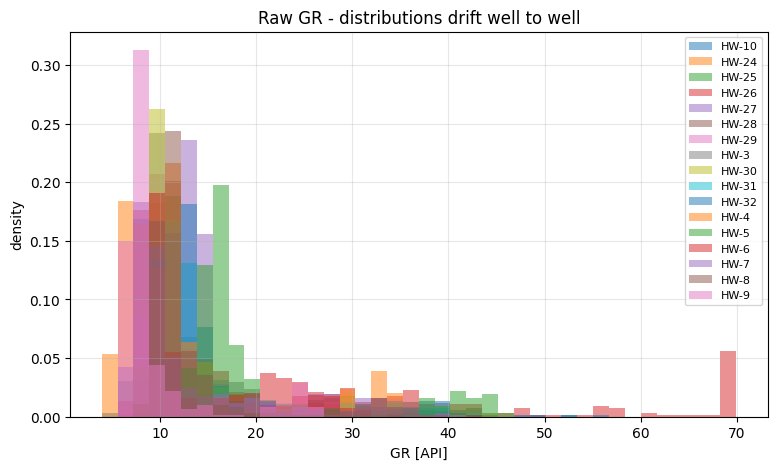

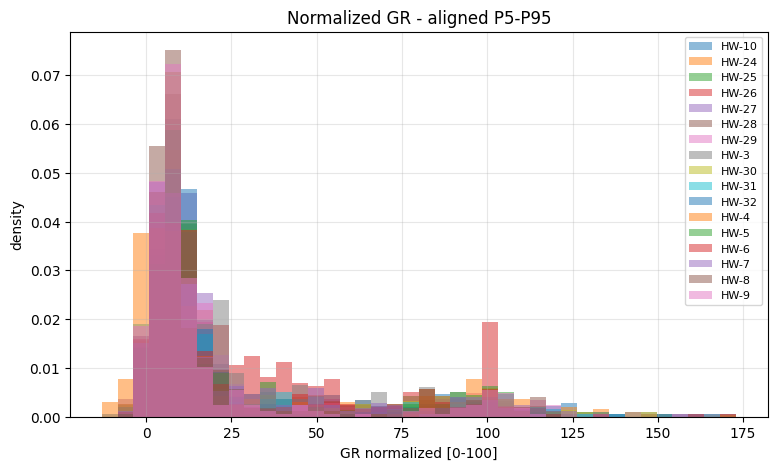

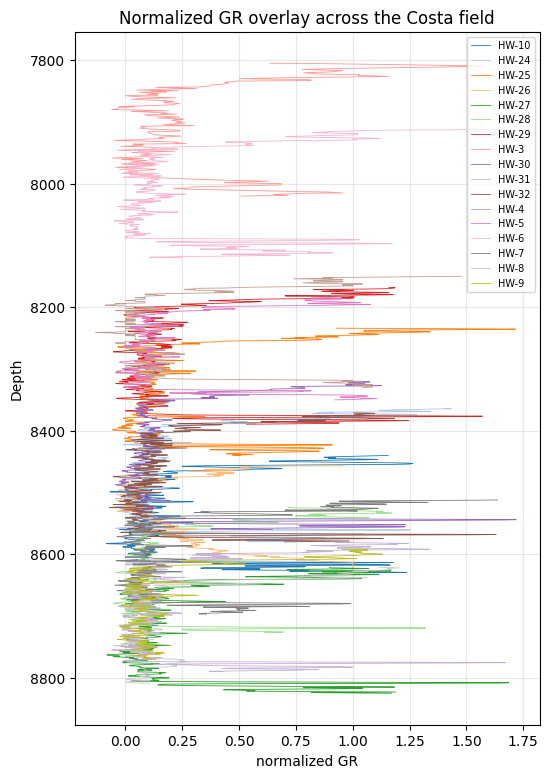

In [6]:
from petrophys.visualization import (
    create_histogram_comparison, create_multiwell_overlay,
)

# Normalize each well's GR so its own P5-P95 maps to 0-100.
gr_norm = {}
for w in wells:
    gr = w.get("GR").data
    lo, hi = np.nanpercentile(gr, [5, 95])
    gr_norm[w.name] = normalize_log(gr, log_min=0.0, log_max=100.0, log_low=lo, log_high=hi)

# Distribution comparison before vs after normalization (library histogram helper).
raw_dists = {w.name: w.get("GR").data for w in wells}
fig, ax = create_histogram_comparison(
    raw_dists, bins=40, density=True,
    xlabel="GR [API]", title="Raw GR - distributions drift well to well",
)
plt.show()

fig, ax = create_histogram_comparison(
    gr_norm, bins=40, density=True,
    xlabel="GR normalized [0-100]", title="Normalized GR - aligned P5-P95",
)
plt.show()

# Same story as a curve-vs-depth overlay: normalize=True robustly scales each
# well's GR so their shapes line up on one axis.
fig, ax = create_multiwell_overlay(
    wells, "GR", normalize=True,
    title="Normalized GR overlay across the Costa field", figsize=(6, 9),
)
plt.show()

After normalization the histograms line up: a given normalized GR now reads on the same
relative scale in every well - provided the shifts we removed really were acquisition
effects. That is the precondition for pooling wells or ranking them on the same scale.

## 4. Per-well reservoir metrics

For each interpreted well we summarise the pay interval. Using the `NET_PAY` flag as the
mask, we compute:

- **net pay** (ft) = pay samples x sample step,
- **average PHIE** and **average Sw** within pay,
- an **HCPV proxy** = `sum(PHIE * (1 - Sw) * dz)` over pay (hydrocarbon pore-volume per
  unit area; a relative volumetric indicator, not a booked reserve).

In [7]:
def well_metrics(w):
    depth = w.depth
    step = w.step or float(np.nanmedian(np.abs(np.diff(depth))))
    phie = w.get("PHIE").data
    sw = w.get("SW").data
    pay = np.nan_to_num(w.get("NET_PAY").data) > 0.5
    gross = float(np.nanmax(depth) - np.nanmin(depth))
    net_pay = float(pay.sum() * step)
    if pay.any():
        avg_phie = float(np.nanmean(phie[pay]))
        avg_sw = float(np.nanmean(sw[pay]))
        hcpv = float(np.nansum(phie[pay] * (1.0 - sw[pay])) * step)
    else:
        avg_phie = avg_sw = np.nan
        hcpv = 0.0
    ntg = net_pay / gross if gross > 0 else np.nan
    return {
        "well": w.name,
        "gross_ft": round(gross, 1),
        "net_pay_ft": round(net_pay, 1),
        "NTG": round(ntg, 2),
        "avg_PHIE": round(avg_phie, 3),
        "avg_Sw": round(avg_sw, 3),
        "HCPV_ftv": round(hcpv, 2),
    }

portfolio = pd.DataFrame([well_metrics(w) for w in processed.values()])
portfolio = portfolio.sort_values("HCPV_ftv", ascending=False).reset_index(drop=True)
print(portfolio.to_string(index=False))

 well  gross_ft  net_pay_ft  NTG  avg_PHIE  avg_Sw  HCPV_ftv
HW-30     240.0       211.5 0.88     0.282   0.138     51.97
HW-29     222.0       187.5 0.84     0.272   0.075     47.30
 HW-3     215.0       176.5 0.82     0.225   0.098     35.75
HW-25     206.0       146.5 0.71     0.224   0.074     30.47
HW-24     216.0       160.5 0.74     0.223   0.241     27.19
 HW-6     208.0       143.5 0.69     0.230   0.223     25.77
HW-32     209.0       121.0 0.58     0.285   0.314     23.61
HW-10     190.0        33.5 0.18     0.228   0.513      3.74
HW-26     172.0        41.0 0.24     0.140   0.374      3.59
HW-28     203.0         7.5 0.04     0.169   0.489      0.65
 HW-4     180.0         4.5 0.03     0.164   0.547      0.33
 HW-9     203.0         1.0 0.00     0.181   0.550      0.08
HW-27     204.0         0.5 0.00     0.213   0.600      0.04
 HW-8     195.0         0.5 0.00     0.103   0.520      0.02
HW-31     210.0         0.0 0.00       NaN     NaN      0.00
 HW-5     168.0         

### Field roll-up

Summing across the field gives the headline numbers, and counting pay-bearing wells shows
how concentrated the value is. Note that the field average PHIE and Sw printed below are
**unweighted means of the per-well pay averages** - each pay-bearing well counts equally,
regardless of how thick its pay is (they are not net-pay-weighted).

In [8]:
pay_wells = portfolio[portfolio.net_pay_ft > 0]
print("wells in field           :", len(portfolio))
print("wells with net pay        :", len(pay_wells))
print("total net pay (ft)        : %.1f" % portfolio.net_pay_ft.sum())
print("field average PHIE (pay)  : %.3f" % pay_wells.avg_PHIE.mean())
print("field average Sw (pay)    : %.3f" % pay_wells.avg_Sw.mean())
print("total HCPV proxy (ft.v/v) : %.1f" % portfolio.HCPV_ftv.sum())
top3 = pay_wells.nlargest(3, "HCPV_ftv").well.tolist()
print("top 3 wells by HCPV proxy :", top3)

wells in field           : 17
wells with net pay        : 14
total net pay (ft)        : 1235.5
field average PHIE (pay)  : 0.210
field average Sw (pay)    : 0.340
total HCPV proxy (ft.v/v) : 250.5
top 3 wells by HCPV proxy : ['HW-30', 'HW-29', 'HW-3']


## 5. Cross-well summary plot

Two charts rank the field. The first is a **ranked horizontal bar chart of net pay per
well** (single color, widest bar at top) - the quantity view. The second shows the
pay-bearing wells as **grouped ranked bars**: the HCPV proxy alongside average PHIE x100
and average Sw x100 (scaled so all three share one axis), ranked by HCPV proxy. Read
together they separate thin-but-rich from thick-but-lean wells.

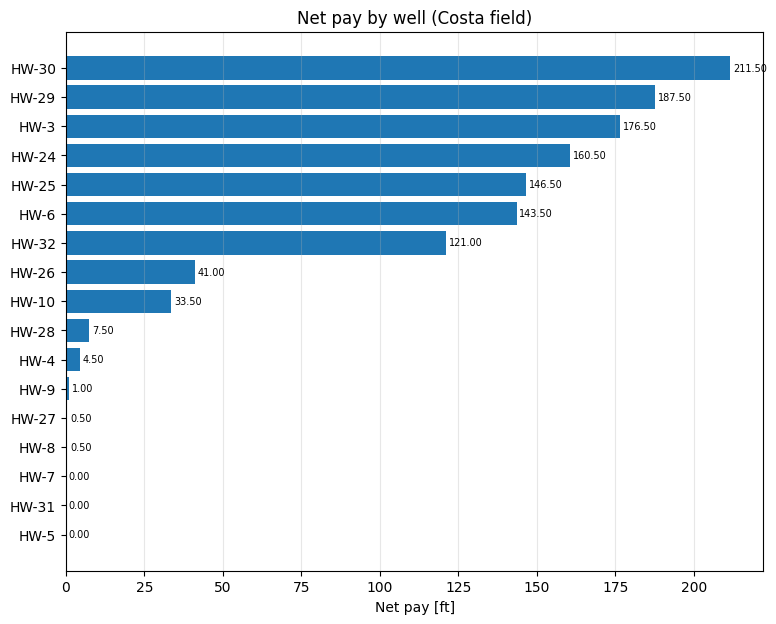

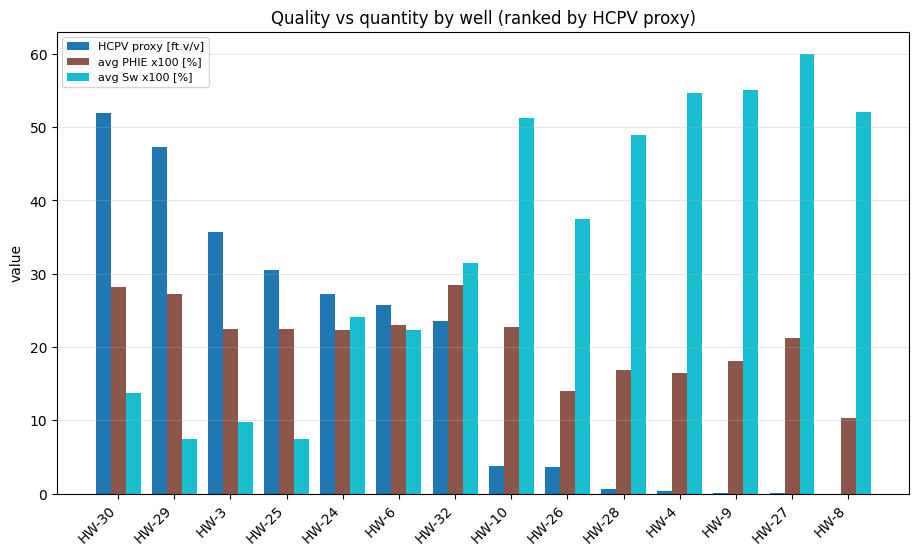

In [9]:
from petrophys.visualization import create_bar_comparison

# Left view: net pay per well, horizontal ranked bars (widest at top).
fig, ax = create_bar_comparison(
    portfolio.well.tolist(), portfolio.net_pay_ft.tolist(),
    horizontal=True, sort_by=0, descending=True, value_labels=True,
    xlabel="Net pay [ft]", title="Net pay by well (Costa field)",
    figsize=(9, 7),
)
plt.show()

# Right view: the quality-vs-quantity roll-up as grouped ranked bars -
# HCPV proxy (quantity) alongside average porosity scaled to the same axis
# (x100, quality) and average Sw (x100), ranked by HCPV.
pw = portfolio[portfolio.net_pay_ft > 0]
grouped = {
    "HCPV proxy [ft.v/v]": pw.HCPV_ftv.tolist(),
    "avg PHIE x100 [%]": (pw.avg_PHIE * 100).tolist(),
    "avg Sw x100 [%]": (pw.avg_Sw * 100).tolist(),
}
fig, ax = create_bar_comparison(
    pw.well.tolist(), grouped, sort_by=0, descending=True,
    ylabel="value", title="Quality vs quantity by well (ranked by HCPV proxy)",
    figsize=(11, 6),
)
plt.show()

## Pitfalls & parameter choices

- **`BatchProcessor` swallows per-well failures.** Always inspect `get_summary()` and
  `BatchResult.errors`; a `success_rate` below 1.0 means some wells were skipped, not that
  they were zero-pay.
- **Read metrics off the interpreted well.** The dynamic workflow annotates the well
  **in place**, so `result.well` is the same object you passed in - both carry the new
  `PHIE`/`SW`/`NET_PAY`. Using `result.well` is simply the clearer, more explicit handle
  for "the interpreted well".
- **Normalize before pooling, not after computing.** Normalization is an input-conditioning
  step for cross-well comparison; do not normalize an already-interpreted output curve.
- **Same cutoffs, different recipe: expect small deltas vs CS3.** Case study 3 screens
  this field with a hand-rolled chain (header Archie constants, Arps-corrected Rw) at the
  same standard cutoffs. Its per-well net pay differs from this batch run by up to
  ~10% - that residual is the *recipe* (porosity chain, header-constant Archie with
  Arps-corrected Rw), not the cutoffs.
- **Watch the depth unit.** Costa wells are in **feet**; net pay and HCPV inherit that
  unit. Do not mix them with metric (GeoLink) wells without converting.
- **The HCPV proxy is relative.** `sum(PHIE*(1-Sw)*dz)` is a per-unit-area screening
  indicator for ranking wells, not a volumetric reserve (no area, Bo, or net-to-gross
  area factor).

## Recap

- `BatchProcessor` (or `process_las_directory`) runs the dynamic workflow across a whole
  field and reports a `get_summary()`; keep each `result.well` for the roll-up.
- **Log normalization** (`normalize_log`) removes acquisition drift so wells share one
  scale - the precondition for fair cross-well comparison.
- Masking on `NET_PAY` yields per-well **net pay, average porosity/Sw, and an HCPV proxy**,
  which pool into a portfolio table and field totals.
- A **cross-well summary plot** turns 17 analyses into one ranking that highlights where
  the pay and hydrocarbon volume concentrate.

## Try it yourself

> **Exercise 1.** Re-run the portfolio with stricter cutoffs by passing a `config` to
> `BatchProcessor(config={...})` (e.g. tighter `phie_cutoff`). How does total net pay
> respond, and which marginal wells drop out?
>
> **Exercise 2.** Replace the per-well GR normalization window with a **single field
> reference** (one well's P5-P95 for all). Does that change the ranking of borderline
> wells?
>
> **Exercise 3.** Add average **permeability** in pay to `well_metrics` and add it as
> another bar series in the grouped quality-vs-quantity chart (scale it to share the
> axis, the way PHIE is shown as PHIE x100 - or swap it in for the Sw series). Do the
> highest-HCPV wells also have the best flow capacity?

## What's next

You have completed the Part B advanced track: borehole imaging (16), the visualization
suite (17), and multi-well field studies (18). From here, revisit the agentic layers
(CAMEL / LangGraph / MCP) that wrap these same tools for natural-language Q&A over LAS
files.